# AlphaMissense — Internal exon-junction distance
Does discrimination of pathogenic and benign missense variants decrease near internal exon junctions?

All acquisition, processing, axis construction, evaluation and plotting code is executable below. Run All recalculates derived values. The target is the released AlphaMissense score; no fine-tuning or fresh model inference is performed.

Use Python 3.11 with numpy 1.26.4, pandas 2.2.3, scipy 1.15.3, scikit-learn 1.7.2, statsmodels 0.14.5, biopython 1.85 and matplotlib 3.10.7. Sources need about 1.14 GB; `AM_RAW_INPUTS` can point to a verified raw-input directory.


## 1. Data source/acquisition
Labels use the **July 2, 2026 monthly ClinVar tabular archive**. Coordinates and translations are GENCODE v32. AlphaMissense is the fixed 2023 hg38 release. Exact source URLs, sizes and hashes are below; the clinical source is the stated monthly archive, not a different weekly release.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)


In [2]:
SOURCES = [{'id': 'am_hg38',
  'path': 'inputs/raw/AlphaMissense_hg38.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz',
  'sha256': '0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475',
  'bytes': 642961469},
 {'id': 'clinvar_tab_archive',
  'path': 'inputs/raw/variant_summary_2026-07.txt.gz',
  'url': 'https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/archive/variant_summary_2026-07.txt.gz',
  'sha256': 'b3da921c707ff50cb4822f04d961834a9e89ef864b4c28bb5308245b93ac4077',
  'bytes': 439937684},
 {'id': 'gencode32',
  'path': 'inputs/raw/gencode.v32.annotation.gtf.gz',
  'url': 'https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/gencode.v32.annotation.gtf.gz',
  'sha256': 'da9dc827e9a111c9bde60c55f55b7d37ffebc4649fc01f0745a670240e939ed4',
  'bytes': 43097815},
 {'id': 'gencode32protein',
  'path': 'inputs/raw/gencode.v32.pc_translations.fa.gz',
  'url': 'https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/gencode.v32.pc_translations.fa.gz',
  'sha256': 'cfc212cfa28022ec4a31e04e9b4377b04a6d1fc13343afb7fc9f651f82954704',
  'bytes': 11643034}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))

,path,url,sha256,bytes
0,AlphaMissense_hg38.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475,642961469
1,variant_summary_2026-07.txt.gz,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/tab_delimited/archive/variant_summary_2026-07.txt.gz,b3da921c707ff50cb4822f04d961834a9e89ef864b4c28bb5308245b93ac4077,439937684
2,gencode.v32.annotation.gtf.gz,https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/gencode.v32.annotation.gtf.gz,da9dc827e9a111c9bde60c55f55b7d37ffebc4649fc01f0745a670240e939ed4,43097815
3,gencode.v32.pc_translations.fa.gz,https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_32/gencode.v32.pc_translations...,cfc212cfa28022ec4a31e04e9b4377b04a6d1fc13343afb7fc9f651f82954704,11643034


## 2. Data processing
Retain GRCh38 single-nucleotide alleles with unambiguous pathogenic/likely-pathogenic or benign/likely-benign labels and at least one review star. Join exact genomic alleles to one unambiguous transcript/protein mapping. Exclude position 1, failed amino-acid checks and transcripts without an internal boundary.


In [3]:
AA_RE=re.compile(r"^([ACDEFGHIKLMNPQRSTVWY])(\d+)([ACDEFGHIKLMNPQRSTVWY])$")
ALLOWED_PATH={"Pathogenic","Likely pathogenic","Pathogenic/Likely pathogenic"}
ALLOWED_BENIGN={"Benign","Likely benign","Benign/Likely benign"}
def label_value(value: str) -> int | None:
    if value in ALLOWED_PATH:
        return 1
    if value in ALLOWED_BENIGN:
        return 0
    return None

def review_stars(status: str) -> int:
    s = status.lower()
    if "practice guideline" in s:
        return 4
    if "expert panel" in s:
        return 3
    if "multiple submitters" in s and "no conflicts" in s:
        return 2
    if "criteria provided" in s and "conflict" not in s:
        return 1
    return 0

def load_clinvar() -> tuple[dict, Counter]:
    path = RAW / "variant_summary_2026-07.txt.gz"
    grouped: dict[tuple, list[dict]] = defaultdict(list)
    qc = Counter()
    with gzip.open(path, "rt", newline="") as handle:
        reader = csv.DictReader(handle, delimiter="\t")
        for row in reader:
            qc["clinvar_rows"] += 1
            if row["Assembly"] != "GRCh38" or "germline" not in row["OriginSimple"].lower():
                continue
            qc["grch38_rows"] += 1
            if row["Type"].lower() != "single nucleotide variant":
                continue
            label = label_value(row["ClinicalSignificance"])
            if label is None:
                continue
            stars = review_stars(row["ReviewStatus"])
            if stars < 1:
                qc["excluded_review_lt_1"] += 1
                continue
            chrom = row["Chromosome"]
            pos = row["PositionVCF"]
            ref = row["ReferenceAlleleVCF"].upper()
            alt = row["AlternateAlleleVCF"].upper()
            if chrom not in {str(i) for i in range(1, 23)} | {"X", "Y"}:
                qc["excluded_contig"] += 1
                continue
            if not pos.isdigit() or len(ref) != 1 or len(alt) != 1 or ref == alt:
                qc["excluded_bad_vcf_allele"] += 1
                continue
            key = ("chr" + chrom, int(pos), ref, alt)
            grouped[key].append({
                "label": label,
                "clinical_significance": row["ClinicalSignificance"],
                "review_status": row["ReviewStatus"],
                "review_stars": stars,
                "last_evaluated": row["LastEvaluated"],
                "clinvar_gene": row["GeneSymbol"],
                "variation_id": row["VariationID"],
                "allele_id": row["#AlleleID"],
                "number_submitters": row["NumberSubmitters"],
                "origin": row["OriginSimple"],
            })
    eligible = {}
    for key, rows in grouped.items():
        labels = {r["label"] for r in rows}
        genes = {r["clinvar_gene"] for r in rows}
        if len(labels) != 1 or len(genes) != 1:
            qc["excluded_clinvar_duplicate_disagreement"] += 1
            continue
        rows.sort(key=lambda r: (-r["review_stars"], r["variation_id"], r["allele_id"]))
        chosen = rows[0].copy()
        chosen["clinvar_duplicate_rows"] = len(rows)
        chosen["variation_ids"] = "|".join(sorted({r["variation_id"] for r in rows}))
        eligible[key] = chosen
    qc["eligible_unique_clinvar_alleles"] = len(eligible)
    return eligible, qc

def match_alphamissense(keys: set[tuple], qc: Counter) -> dict:
    path = RAW / "AlphaMissense_hg38.tsv.gz"
    matched: dict[tuple, list[dict]] = defaultdict(list)
    names = ["chrom", "pos", "ref", "alt", "genome", "uniprot_id",
             "transcript_id", "protein_variant", "am_pathogenicity", "am_class"]
    with gzip.open(path, "rt", newline="") as handle:
        reader = csv.reader(handle, delimiter="\t")
        for fields in reader:
            if not fields or fields[0].startswith("#"):
                continue
            qc["alphamissense_rows_scanned"] += 1
            key = (fields[0], int(fields[1]), fields[2], fields[3])
            if key in keys:
                matched[key].append(dict(zip(names, fields)))
    qc["clinvar_alleles_with_am_match"] = len(matched)
    unique = {}
    for key, rows in matched.items():
        signatures = {(r["uniprot_id"], r["transcript_id"], r["protein_variant"],
                       r["am_pathogenicity"]) for r in rows}
        if len(signatures) != 1:
            qc["excluded_ambiguous_am_mapping"] += 1
            continue
        unique[key] = rows[0]
    return unique

def parse_attrs(text: str) -> dict:
    out = {}
    for item in text.rstrip(";").split("; "):
        if " " in item:
            key, value = item.split(" ", 1)
            out[key] = value.strip('"')
    return out

def load_transcripts(wanted: set[str]) -> dict:
    tx = defaultdict(lambda: {"exons": [], "gene": None, "strand": None})
    with gzip.open(RAW / "gencode.v32.annotation.gtf.gz", "rt") as handle:
        for line in handle:
            if not line or line[0] == "#":
                continue
            f = line.rstrip("\n").split("\t")
            if f[2] != "exon":
                continue
            attrs = parse_attrs(f[8])
            tid = attrs.get("transcript_id")
            if tid not in wanted:
                continue
            tx[tid]["exons"].append((int(f[3]), int(f[4])))
            tx[tid]["gene"] = attrs.get("gene_id", "").split(".")[0]
            tx[tid]["strand"] = f[6]
    for value in tx.values():
        value["exons"].sort()
    return dict(tx)

def load_sequences(wanted: set[str]) -> dict[str, str]:
    seqs = {}
    current = None
    chunks = []
    with gzip.open(RAW / "gencode.v32.pc_translations.fa.gz", "rt") as handle:
        for line in handle:
            if line.startswith(">"):
                if current in wanted:
                    seqs[current] = "".join(chunks)
                parts = line[1:].rstrip().split("|")
                current = parts[1] if len(parts) > 1 else None
                chunks = []
            else:
                chunks.append(line.strip())
        if current in wanted:
            seqs[current] = "".join(chunks)
    return seqs


In [4]:
clinvar,qc=load_clinvar()
am=match_alphamissense(set(clinvar),qc)
wanted={r["transcript_id"] for r in am.values()}
tx=load_transcripts(wanted)
seqs=load_sequences(wanted)
display(pd.Series(dict(qc),name="count").to_frame())


,count
clinvar_rows,8991566
grch38_rows,4149441
excluded_bad_vcf_allele,510
excluded_contig,1711
eligible_unique_clinvar_alleles,1460394
alphamissense_rows_scanned,71697556
clinvar_alleles_with_am_match,204884
excluded_ambiguous_am_mapping,2746


## 3. Axis definition and level construction
Distance is the minimum exonic base distance to an internal boundary on the exact versioned transcript; the boundary base is 0. External transcript edges are excluded. Levels run far→junction. Partitions use input-side gene identifiers.
Levels: ≥31,11–30,3–10,0–2nt. The first 64 bits of SHA256(version-stripped GENCODE geneID) modulo 10 assign discovery 0–3 and confirmation 4–9. Only germline records are included; proteins spanning partitions are excluded.


In [5]:
def splice_geometry(pos: int, exons: list[tuple[int, int]]) -> tuple[int, int, bool] | None:
    if len(exons) < 2:
        return None
    hits = []
    for i, (start, end) in enumerate(exons):
        if start <= pos <= end:
            candidates = []
            if i > 0:
                candidates.append(pos - start)
            if i < len(exons) - 1:
                candidates.append(end - pos)
            if candidates:
                hits.append((min(candidates), i + 1, i in {0, len(exons) - 1}))
    if len(hits) != 1:
        return None
    return hits[0]

def axis_level(distance: int) -> tuple[int, str]:
    if distance >= 31:
        return 0, "far"
    if distance >= 11:
        return 1, "mid"
    if distance >= 3:
        return 2, "proximal"
    return 3, "splice_region"

def split_cluster(gene):
    value=int(hashlib.sha256(gene.encode()).hexdigest()[:16],16)%10
    return 'discovery' if value<4 else 'confirmation'


In [6]:
blosum = substitution_matrices.load("BLOSUM62")
rows = []
for key, model in am.items():
    meta = clinvar[key]
    match = AA_RE.match(model["protein_variant"])
    if not match:
        qc["excluded_bad_protein_variant"] += 1
        continue
    ref_aa, aa_pos_text, alt_aa = match.groups()
    aa_pos = int(aa_pos_text)
    if aa_pos == 1:
        qc["excluded_start_loss_position1"] += 1
        continue
    transcript = model["transcript_id"]
    if transcript not in tx:
        qc["excluded_transcript_missing_gtf"] += 1
        continue
    sequence = seqs.get(transcript)
    if not sequence or aa_pos > len(sequence):
        qc["excluded_translation_missing_or_short"] += 1
        continue
    if sequence[aa_pos - 1] != ref_aa:
        qc["excluded_reference_aa_mismatch"] += 1
        continue
    geom = splice_geometry(key[1], tx[transcript]["exons"])
    if geom is None:
        qc["excluded_no_unique_internal_splice_distance"] += 1
        continue
    distance, exon_ordinal, terminal_exon = geom
    level, level_name = axis_level(distance)
    gene = tx[transcript]["gene"] or meta["clinvar_gene"] or model["uniprot_id"]
    partition = split_cluster(gene)
    rows.append({
        "variant_key": f"{key[0]}:{key[1]}:{key[2]}:{key[3]}",
        "chrom": key[0], "pos": key[1], "ref": key[2], "alt": key[3],
        "gene": gene, "clinvar_gene": meta["clinvar_gene"],
        "uniprot_id": model["uniprot_id"], "transcript_id": transcript,
        "protein_variant": model["protein_variant"], "ref_aa": ref_aa,
        "aa_pos": aa_pos, "alt_aa": alt_aa, "protein_length": len(sequence),
        "position_fraction": aa_pos / len(sequence), "strand": tx[transcript]["strand"],
        "exon_ordinal_genomic": exon_ordinal, "terminal_exon": terminal_exon,
        "d_splice_bp": distance, "axis_level": level, "axis_name": level_name,
        "partition": partition, "review_status": meta["review_status"],
        "review_stars": meta["review_stars"], "last_evaluated": meta["last_evaluated"],
        "number_submitters": meta["number_submitters"], "origin": meta["origin"],
        "variation_ids": meta["variation_ids"],
        "blosum62": float(blosum[ref_aa, alt_aa]),
        "blosum_pathogenicity": -float(blosum[ref_aa, alt_aa]),
        "label": meta["label"], "clinical_significance": meta["clinical_significance"],
        "am_pathogenicity": float(model["am_pathogenicity"]), "am_class": model["am_class"],
    })
df = pd.DataFrame(rows).sort_values(["partition", "gene", "variant_key"])

cross=df.groupby("uniprot_id").partition.nunique();excluded=cross[cross>1].index
qc["excluded_cross_partition_protein_rows"]=int(df.uniprot_id.isin(excluded).sum())
df=df[~df.uniprot_id.isin(excluded)].copy()
assert df.variant_key.is_unique
assert df.groupby("gene").partition.nunique().max()==1
display(df.groupby(["partition","axis_level","axis_name"]).agg(rows=("label","size"),genes=("gene","nunique"),pathogenic=("label","sum"),median_distance=("d_splice_bp","median")))
display(df[["variant_key","gene","transcript_id","d_splice_bp","axis_level","partition"]].head(10))


rows  genes  pathogenic  \
partition    axis_level axis_name                                 
confirmation 0          far            80635   7827       21421   
             1          mid            23342   4975        8924   
             2          proximal        9620   3241        3789   
             3          splice_region   3694   1640        2184   
discovery    0          far            54022   5226       15088   
             1          mid            16318   3299        6715   
             2          proximal        6828   2218        2874   
             3          splice_region   2604   1109        1555   

                                       median_distance  
partition    axis_level axis_name                       
confirmation 0          far                       85.0  
             1          mid                       20.0  
             2          proximal                   7.0  
             3          splice_region              1.0  
discovery    0          far                       82.0  
             1          mid                       20.0  
             2          proximal                   7.0  
             3          splice_region              1.0

,variant_key,gene,transcript_id,d_splice_bp,axis_level,partition
190520,chrX:100633518:C:T,ENSG00000000003,ENST00000373020.9,21,1,confirmation
190521,chrX:100635575:C:T,ENSG00000000003,ENST00000373020.9,17,1,confirmation
117847,chr20:50935173:A:G,ENSG00000000419,ENST00000371588.9,63,0,confirmation
117848,chr20:50942054:C:G,ENSG00000000419,ENST00000371588.9,23,1,confirmation
117849,chr20:50942070:C:A,ENSG00000000419,ENST00000371588.9,39,0,confirmation
117850,chr20:50945848:T:C,ENSG00000000419,ENST00000371588.9,1,3,confirmation
117851,chr20:50948650:G:C,ENSG00000000419,ENST00000371588.9,12,1,confirmation
117852,chr20:50958492:C:G,ENSG00000000419,ENST00000371588.9,129,0,confirmation
12985,chr1:169854533:C:T,ENSG00000000457,ENST00000367772.8,263,0,confirmation
12986,chr1:169854554:C:T,ENSG00000000457,ENST00000367772.8,284,0,confirmation


## 4. Model results or released scores
The model output is `am_pathogenicity` from the exact hg38 allele join. AUROC ranks pathogenic alleles above benign alleles. The same-variant reference is negative BLOSUM62. Calibration, Brier score, average precision and released 0.34/0.564 thresholds are evaluated separately.


In [7]:
SEED=20260715
LEVELS=[0,1,2,3]
def weighted_auc_sorted(labels: np.ndarray, scores: np.ndarray,
                        row_weights: np.ndarray) -> float:
    order = np.argsort(scores, kind="mergesort")
    y = labels[order]
    s = scores[order]
    w = row_weights[order]
    starts = np.r_[0, np.flatnonzero(s[1:] != s[:-1]) + 1]
    pos = np.add.reduceat(w * (y == 1), starts)
    neg = np.add.reduceat(w * (y == 0), starts)
    p, n = pos.sum(), neg.sum()
    if p <= 0 or n <= 0:
        return np.nan
    neg_before = np.cumsum(neg) - neg
    return float(np.sum(pos * (neg_before + 0.5 * neg)) / (p * n))

def ece(y: np.ndarray, score: np.ndarray) -> float:
    bins = np.minimum((score * 10).astype(int), 9)
    value = 0.0
    for b in range(10):
        keep = bins == b
        if keep.any():
            value += keep.mean() * abs(y[keep].mean() - score[keep].mean())
    return float(value)

def calibration(y: np.ndarray, score: np.ndarray) -> tuple[float, float]:
    z = np.log(np.clip(score, 1e-6, 1 - 1e-6) /
               np.clip(1 - score, 1e-6, 1 - 1e-6))
    try:
        fit = sm.GLM(y, sm.add_constant(z), family=sm.families.Binomial()).fit()
        return float(fit.params[0]), float(fit.params[1])
    except Exception:
        return np.nan, np.nan

def level_metrics(g: pd.DataFrame) -> dict:
    y = g.label.to_numpy(int)
    s = g.am_pathogenicity.to_numpy(float)
    ref = g.blosum_pathogenicity.to_numpy(float)
    intercept, slope = calibration(y, s)
    called = (s < 0.34) | (s > 0.564)
    correct_call = ((s < 0.34) & (y == 0)) | ((s > 0.564) & (y == 1))
    return {
        "axis_level": int(g.axis_level.iloc[0]), "axis_name": g.axis_name.iloc[0],
        "rows": len(g), "genes": g.gene.nunique(), "proteins": g.uniprot_id.nunique(),
        "pathogenic": int(y.sum()), "benign": int((1 - y).sum()),
        "prevalence": y.mean(), "median_d_splice_bp": g.d_splice_bp.median(),
        "q25_d_splice_bp": g.d_splice_bp.quantile(.25),
        "q75_d_splice_bp": g.d_splice_bp.quantile(.75),
        "min_d_splice_bp": g.d_splice_bp.min(), "max_d_splice_bp": g.d_splice_bp.max(),
        "am_auroc": roc_auc_score(y, s),
        "blosum_auroc": roc_auc_score(y, ref),
        "am_auprc": average_precision_score(y, s),
        "brier": np.mean((s - y) ** 2), "ece_10": ece(y, s),
        "calibration_intercept": intercept, "calibration_slope": slope,
        "sensitivity_gt_0564": np.mean(s[y == 1] > 0.564),
        "specificity_at_0564": np.mean(s[y == 0] <= 0.564),
        "sensitivity_at_034": np.mean(s[y == 1] >= 0.34),
        "specificity_lt_034": np.mean(s[y == 0] < 0.34),
        "ambiguous_fraction": np.mean((s >= 0.34) & (s <= 0.564)),
        "called_fraction": called.mean(),
        "called_accuracy": correct_call.sum() / called.sum() if called.any() else np.nan,
    }

def cluster_bootstrap(df: pd.DataFrame, reps: int = 2000) -> pd.DataFrame:
    genes = sorted(df.gene.unique())
    gene_to_i = {g: i for i, g in enumerate(genes)}
    arrays = {}
    for lv in LEVELS:
        g = df[df.axis_level == lv]
        arrays[lv] = {
            "y": g.label.to_numpy(int),
            "am": g.am_pathogenicity.to_numpy(float),
            "ref": g.blosum_pathogenicity.to_numpy(float),
            "gi": g.gene.map(gene_to_i).to_numpy(int),
        }
    rng = np.random.default_rng(SEED)
    out = []
    n = len(genes)
    for b in range(reps):
        counts = np.bincount(rng.integers(0, n, n), minlength=n).astype(float)
        row = {"replicate": b}
        for lv, a in arrays.items():
            w = counts[a["gi"]]
            row[f"am_auc_{lv}"] = weighted_auc_sorted(a["y"], a["am"], w)
            row[f"ref_auc_{lv}"] = weighted_auc_sorted(a["y"], a["ref"], w)
        row["d_am"] = row["am_auc_0"] - row["am_auc_3"]
        row["d_ref"] = row["ref_auc_0"] - row["ref_auc_3"]
        row["contrast_am_minus_ref"] = row["d_am"] - row["d_ref"]
        out.append(row)
    return pd.DataFrame(out)

def ci(values: pd.Series) -> tuple[float, float]:
    return tuple(np.nanquantile(values, [.025, .975]))

def matched_extremes(df: pd.DataFrame) -> dict:
    x = df[df.axis_level.isin([0, 3])].copy()
    selected = []
    strata_used = 0
    for _, g in x.groupby(["gene", "label", "ref_aa", "alt_aa"], sort=True):
        far = g[g.axis_level == 0].sort_values("variant_key")
        near = g[g.axis_level == 3].sort_values("variant_key")
        n = min(len(far), len(near))
        if n:
            selected.extend([far.iloc[:n], near.iloc[:n]])
            strata_used += 1
    if not selected:
        return {"rows": 0, "strata": 0}
    m = pd.concat(selected, ignore_index=True)
    result = {"rows": len(m), "strata": strata_used, "genes": m.gene.nunique()}
    for lv, g in m.groupby("axis_level"):
        result[f"level_{lv}_rows"] = len(g)
        result[f"level_{lv}_auc"] = roc_auc_score(g.label, g.am_pathogenicity)
        result[f"level_{lv}_ref_auc"] = roc_auc_score(g.label, g.blosum_pathogenicity)
    result["am_degradation"] = result.get("level_0_auc", np.nan) - result.get("level_3_auc", np.nan)
    result["ref_degradation"] = result.get("level_0_ref_auc", np.nan) - result.get("level_3_ref_auc", np.nan)
    return result

def macro_gene_level(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for (gene, lv), g in df.groupby(["gene", "axis_level"]):
        if g.label.nunique() == 2 and min(g.label.value_counts()) >= 2:
            rows.append({"gene": gene, "axis_level": lv, "n": len(g),
                         "am_auc": roc_auc_score(g.label, g.am_pathogenicity),
                         "blosum_auc": roc_auc_score(g.label, g.blosum_pathogenicity)})
    return pd.DataFrame(rows)

def confound_regression(df: pd.DataFrame) -> dict:
    x = df.copy()
    x["score_z"] = (x.am_pathogenicity - x.am_pathogenicity.mean()) / x.am_pathogenicity.std()
    x["level_z"] = x.axis_level.astype(float)
    x["log_length"] = np.log(x.protein_length)
    formula = ("label ~ score_z * level_z + blosum62 + position_fraction + log_length + "
               "review_stars + C(ref_aa) + C(alt_aa) + C(strand) + C(terminal_exon)")
    fit = smf.glm(formula, data=x, family=sm.families.Binomial()).fit(
        cov_type="cluster", cov_kwds={"groups": x.gene}, maxiter=100)
    names = ["score_z", "level_z", "score_z:level_z", "blosum62",
             "position_fraction", "log_length", "review_stars"]
    return {name: {"coefficient": float(fit.params[name]),
                   "se_cluster_gene": float(fit.bse[name]),
                   "p_value": float(fit.pvalues[name])} for name in names}


In [8]:
tables={};bootstraps={};summaries={};control_rows=[]
for partition in ['discovery','confirmation']:
    panel=df[df.partition.eq(partition)].copy()
    table=pd.DataFrame([level_metrics(g) for _,g in panel.groupby('axis_level')]).sort_values('axis_level')
    boot=cluster_bootstrap(panel,reps=2000)
    for level in LEVELS:
        for predictor,column in [('am','am_auc'),('ref','blosum_auc')]:
            lo,hi=ci(boot[f'{predictor}_auc_{level}'])
            table.loc[table.axis_level.eq(level),column+'_low']=lo
            table.loc[table.axis_level.eq(level),column+'_high']=hi
    tables[partition]=table;bootstraps[partition]=boot
    summaries[partition]={'AM_far_minus_junction':float(table.iloc[0].am_auroc-table.iloc[-1].am_auroc),
       'AM_CI':list(ci(boot.d_am)),'reference_far_minus_junction':float(table.iloc[0].blosum_auroc-table.iloc[-1].blosum_auroc),
       'reference_CI':list(ci(boot.d_ref)),'paired_difference_CI':list(ci(boot.contrast_am_minus_ref))}
    display(Markdown('**'+partition.title()+'**'));display(table)
display(pd.DataFrame(summaries).T)


**Discovery**

,axis_level,axis_name,rows,genes,proteins,pathogenic,benign,prevalence,median_d_splice_bp,q25_d_splice_bp,...,specificity_at_0564,sensitivity_at_034,specificity_lt_034,ambiguous_fraction,called_fraction,called_accuracy,am_auc_low,am_auc_high,blosum_auc_low,blosum_auc_high
0,0,far,54022,5226,5226,15088,38934,0.279294,82.0,50.0,...,0.950686,0.894353,0.908769,0.052960,0.947040,0.931315,0.956988,0.966601,0.673856,0.693282
1,1,mid,16318,3299,3299,6715,9603,0.411509,20.0,16.0,...,0.926898,0.912733,0.874727,0.060608,0.939392,0.915976,0.949869,0.961983,0.692513,0.717711
2,2,proximal,6828,2218,2218,2874,3954,0.420914,7.0,5.0,...,0.926151,0.906402,0.871270,0.059754,0.940246,0.912617,0.945228,0.960690,0.692774,0.726954
3,3,splice_region,2604,1109,1109,1555,1049,0.597158,1.0,0.0,...,0.920877,0.814791,0.859867,0.077573,0.922427,0.845545,0.900078,0.930130,0.617529,0.668898


**Confirmation**

,axis_level,axis_name,rows,genes,proteins,pathogenic,benign,prevalence,median_d_splice_bp,q25_d_splice_bp,...,specificity_at_0564,sensitivity_at_034,specificity_lt_034,ambiguous_fraction,called_fraction,called_accuracy,am_auc_low,am_auc_high,blosum_auc_low,blosum_auc_high
0,0,far,80635,7827,7831,21421,59214,0.265654,85.0,50.0,...,0.945942,0.901779,0.898250,0.054641,0.945359,0.930407,0.957813,0.966702,0.677889,0.704227
1,1,mid,23342,4975,4976,8924,14418,0.382315,20.0,16.0,...,0.935151,0.917414,0.881190,0.059335,0.940665,0.923851,0.957990,0.966649,0.703175,0.730145
2,2,proximal,9620,3241,3241,3789,5831,0.393867,7.0,5.0,...,0.924027,0.927685,0.871377,0.057796,0.942204,0.920896,0.954055,0.967339,0.706379,0.735943
3,3,splice_region,3694,1640,1640,2184,1510,0.591229,1.0,0.0,...,0.918543,0.817308,0.862252,0.069031,0.930969,0.848212,0.904241,0.929856,0.604651,0.651208


,AM_far_minus_junction,AM_CI,reference_far_minus_junction,reference_CI,paired_difference_CI
discovery,0.046156,"[0.032513710926300114, 0.061552956725570825]",0.039747,"[0.015886791128034948, 0.06518074138509647]","[-0.01712199273723657, 0.03165297156985268]"
confirmation,0.044547,"[0.033469104807644166, 0.056993270581307855]",0.061129,"[0.03452794111623308, 0.08984120411520277]","[-0.0436360515776882, 0.008430595385746077]"


## 5. Curves and controls
Gene resampling supplies 2,000 paired target/reference intervals. Controls check gene+label+amino-acid-matched extremes, within-gene AUROCs, review status, evaluation era, length, strand and terminal-exon composition. The regression controls substitution chemistry and sequence position/length.


,matched_extremes
rows,2176.000000
strata,839.000000
genes,432.000000
level_0_rows,1088.000000
level_0_auc,0.974943
level_0_ref_auc,0.745810
level_3_rows,1088.000000
level_3_auc,0.952602
level_3_ref_auc,0.745810
am_degradation,0.022341


,coefficient,se_cluster_gene,p_value
score_z,2.601274,0.040666,0.000000e+00
level_z,0.327388,0.025817,7.505392e-37
score_z:level_z,-0.118691,0.020538,7.511675e-09
blosum62,-0.077932,0.015283,3.409646e-07
position_fraction,0.204118,0.078168,9.020497e-03
log_length,-0.687612,0.091446,5.506093e-14
review_stars,0.507305,0.063803,1.848876e-15


,genes,mean_AM,mean_reference
axis_level,,,
0,1197,0.948522,0.695538
1,493,0.946075,0.707990
2,178,0.954870,0.718591
3,52,0.881940,0.630980


,factor,stratum,level,rows,AM_AUROC,reference_AUROC
0,review_group,1 star,0,56801,0.962700,0.697522
1,review_group,1 star,1,16027,0.963269,0.723185
2,review_group,1 star,2,6654,0.959457,0.736419
3,review_group,1 star,3,2435,0.926719,0.642969
4,review_group,2+ stars,0,23834,0.962035,0.671264
5,review_group,2+ stars,1,7315,0.961577,0.700403
6,review_group,2+ stars,2,2966,0.965678,0.692491
7,review_group,2+ stars,3,1259,0.897681,0.601296
8,evaluation_era,earlier/unknown,0,29947,0.958820,0.688449
9,evaluation_era,earlier/unknown,1,9047,0.961747,0.716053


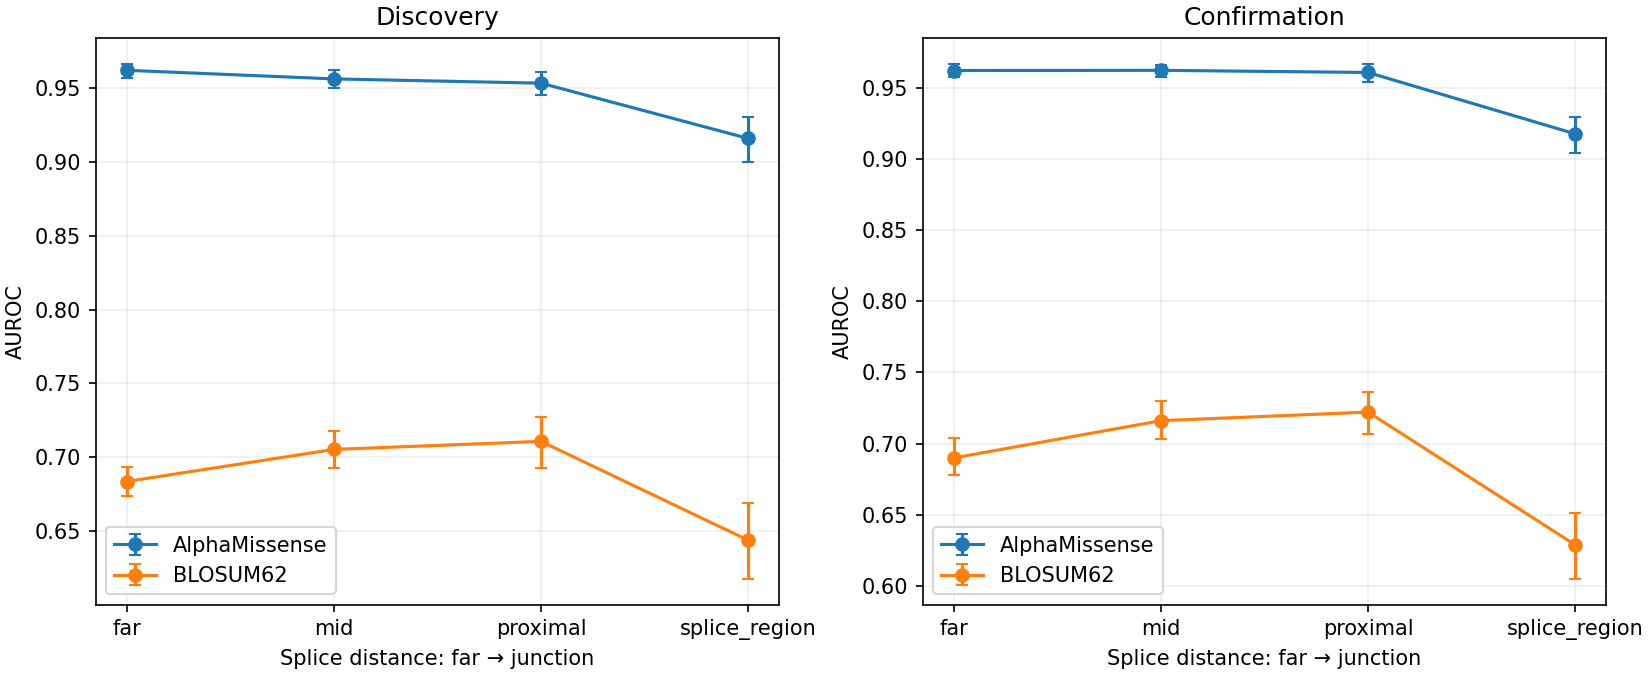

In [9]:
confirmation=df[df.partition.eq('confirmation')].copy()
matched=matched_extremes(confirmation);macro=macro_gene_level(confirmation);regression=confound_regression(confirmation)
display(pd.Series(matched,name='matched_extremes').to_frame());display(pd.DataFrame(regression).T)
display(macro.groupby('axis_level').agg(genes=('gene','nunique'),mean_AM=('am_auc','mean'),mean_reference=('blosum_auc','mean')))
confirmation['review_group']=np.where(confirmation.review_stars>=2,'2+ stars','1 star')
confirmation['evaluation_era']=np.where(pd.to_datetime(confirmation.last_evaluated,errors='coerce')>='2023-09-22','since model publication','earlier/unknown')
confirmation['length_quartile']=pd.qcut(confirmation.protein_length,4,labels=False,duplicates='drop')
for factor in ['review_group','evaluation_era','length_quartile','strand','terminal_exon']:
    for value,subset in confirmation.groupby(factor):
        for level,g in subset.groupby('axis_level'):
            if g.label.nunique()==2 and g.label.value_counts().min()>=20:
                control_rows.append(dict(factor=factor,stratum=str(value),level=level,rows=len(g),
                    AM_AUROC=roc_auc_score(g.label,g.am_pathogenicity),reference_AUROC=roc_auc_score(g.label,g.blosum_pathogenicity)))
controls=pd.DataFrame(control_rows);display(controls)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,(partition,table) in zip(axes,tables.items()):
    for metric,prefix,label in [('am_auroc','am_auc','AlphaMissense'),('blosum_auroc','blosum_auc','BLOSUM62')]:
        y=table[metric].to_numpy();lo=table[prefix+'_low'].to_numpy();hi=table[prefix+'_high'].to_numpy()
        ax.errorbar(table.axis_level,y,yerr=np.maximum(0,np.vstack([y-lo,hi-y])),marker='o',capsize=3,label=label)
    ax.set_xticks(table.axis_level,table.axis_name);ax.set(title=partition.title(),xlabel='Splice distance: far → junction',ylabel='AUROC');ax.legend();ax.grid(alpha=.2)
buf=BytesIO();fig.savefig(buf,format='png',dpi=150);display(Image(data=buf.getvalue()));fig.savefig(OUTPUT/'curve.png',dpi=150);plt.close(fig)


## 6. What the agent decided, and why
The calculated confirmation contrast and gene-bootstrap interval determine the decision. A positive far-minus-junction difference means worse discrimination at junctions. The reference characterizes whether the difficulty is shared.


In [10]:
s=summaries['confirmation'];degrades=s['AM_far_minus_junction']>0 and s['AM_CI'][0]>0
decision='Accept: discrimination decreases near internal exon junctions' if degrades else 'Do not accept a supported decrease near junctions on this panel'
print(decision);display(pd.Series(s,name='confirmation_result').to_frame())
print('Reference decline:',s['reference_far_minus_junction'],'| paired target-minus-reference interval:',s['paired_difference_CI'])
df.to_csv(OUTPUT/'individual_variants.csv.gz',index=False,compression='gzip')
for partition,table in tables.items():table.to_csv(OUTPUT/(partition+'_curve.csv'),index=False)
controls.to_csv(OUTPUT/'controls.csv',index=False);macro.to_csv(OUTPUT/'within_gene.csv',index=False)
record={'completed':True,'host':platform.node(),'elapsed_seconds':time.time()-STARTED,'sources':source_receipts,
        'rows':len(df),'decision':decision,'results':summaries,'custom_external_code_used':False,'new_model_inference':False}
(OUTPUT/'execution.json').write_text(json.dumps(record,indent=2)+'\n')


Accept: discrimination decreases near internal exon junctions


,confirmation_result
AM_far_minus_junction,0.044547
AM_CI,"[0.033469104807644166, 0.056993270581307855]"
reference_far_minus_junction,0.061129
reference_CI,"[0.03452794111623308, 0.08984120411520277]"
paired_difference_CI,"[-0.0436360515776882, 0.008430595385746077]"


Reference decline: 0.06112862101701466 | paired target-minus-reference interval: [-0.0436360515776882, 0.008430595385746077]


2243